In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("E-Commerce Data Analysis Project")
print("Pandas version:", pd.__version__)

E-Commerce Data Analysis Project
Pandas version: 3.1.1


In [2]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("CSV files:")
for file in Path.cwd().rglob("*.csv"):
    print(file)

Current folder: c:\DATA SCINENCE\Ecommerce-Data-Analysis\notebooks
CSV files:


In [3]:
import pandas as pd
from pathlib import Path

# تحديد مجلد البيانات
data_path = Path("../DATA/RAW")

# قراءة بيانات الطلبات
orders = pd.read_csv(data_path / "olist_orders_dataset (7).csv")

# عرض أول 5 صفوف
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
print("Total rows:", orders.shape[0])
print("Total columns:", orders.shape[1])

print("\nMissing values:")
print(orders.isnull().sum())

print("\nDuplicate order IDs:")
print(orders["order_id"].duplicated().sum())

print("\nOrder status distribution:")
print(orders["order_status"].value_counts())

Total rows: 99441
Total columns: 8

Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Duplicate order IDs:
0

Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [5]:
# Filter delivered orders
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Count delivered orders
print("Delivered orders:", len(delivered_orders))

# Count unique order IDs
print(
    "Unique delivered orders:",
    delivered_orders["order_id"].nunique()
)

# Check duplicate order IDs
print(
    "Duplicate delivered orders:",
    delivered_orders["order_id"].duplicated().sum()
)

Delivered orders: 96478
Unique delivered orders: 96478
Duplicate delivered orders: 0


In [6]:
# ============================================
# CUSTOMER DATA VALIDATION
# E-Commerce Data Analysis Project
# ============================================

import pandas as pd
from pathlib import Path

# 1. Define the dataset folder
data_path = Path("../DATA/RAW")

# 2. Find the customers dataset automatically
customer_files = sorted(
    data_path.glob("olist_customers_dataset*.csv")
)

if not customer_files:
    raise FileNotFoundError(
        f"Customers dataset not found in: {data_path.resolve()}"
    )

customer_file = customer_files[0]

print("Customers file found:", customer_file.name)

# 3. Load customers dataset
customers = pd.read_csv(customer_file)

print("Customers dataset loaded successfully!")
print("Total customer records:", len(customers))

# 4. Filter delivered orders
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("\nDelivered orders:", len(delivered_orders))

# 5. Merge delivered orders with customers
delivered_customers = delivered_orders.merge(
    customers[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# 6. Check missing customer IDs
missing_customers = (
    delivered_customers["customer_unique_id"]
    .isna()
    .sum()
)

print("\nMissing customer IDs:", missing_customers)

# 7. Count unique customers
total_customers = (
    delivered_customers["customer_unique_id"]
    .nunique()
)

print("Total unique customers:", total_customers)

# 8. Count unique delivered orders
total_orders = (
    delivered_customers["order_id"]
    .nunique()
)

print("Total delivered orders:", total_orders)

# 9. Check duplicate order IDs
duplicate_orders = (
    delivered_customers["order_id"]
    .duplicated()
    .sum()
)

print("Duplicate delivered orders:", duplicate_orders)

# 10. Validate results against Dashboard
print("\n========== VALIDATION RESULTS ==========")

print(
    "Orders match Dashboard:",
    total_orders == 96478
)

print(
    "Customers match Dashboard:",
    total_customers == 93358
)

print(
    "No missing customer IDs:",
    missing_customers == 0
)

print(
    "No duplicate order IDs:",
    duplicate_orders == 0
)

print("========================================")

Customers file found: olist_customers_dataset (9).csv
Customers dataset loaded successfully!
Total customer records: 99441

Delivered orders: 96478

Missing customer IDs: 0
Total unique customers: 93358
Total delivered orders: 96478
Duplicate delivered orders: 0

========== VALIDATION RESULTS ==========
Orders match Dashboard: True
Customers match Dashboard: True
No missing customer IDs: True
No duplicate order IDs: True


In [7]:
# ============================================
# TOTAL PRODUCT SALES VALIDATION
# E-Commerce Data Analysis Project
# ============================================

import pandas as pd
from pathlib import Path

# 1. Find order items dataset
order_items_files = sorted(
    data_path.glob("olist_order_items_dataset*.csv")
)

if not order_items_files:
    raise FileNotFoundError(
        "Order items dataset was not found!"
    )

if len(order_items_files) > 1:
    raise ValueError(
        f"Multiple order items files found: "
        f"{[f.name for f in order_items_files]}"
    )

order_items_file = order_items_files[0]

print("Order items file:", order_items_file.name)

# 2. Load order items
order_items = pd.read_csv(order_items_file)

print("Total order item rows:", len(order_items))

# 3. Keep items from delivered orders only
delivered_items = order_items.merge(
    delivered_orders[["order_id"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# 4. Calculate product sales
total_product_sales = delivered_items["price"].sum()

# 5. Compare with Dashboard
expected_sales = 13591643.70

print("\n========== SALES VALIDATION ==========")

print(
    f"Calculated Product Sales: R$ {total_product_sales:,.2f}"
)

print(
    f"Dashboard Product Sales:  R$ {expected_sales:,.2f}"
)

print(
    f"Difference: R$ {total_product_sales - expected_sales:,.2f}"
)

print(
    "Sales match Dashboard:",
    abs(total_product_sales - expected_sales) < 0.01
)

print(
    "Unique delivered orders with items:",
    delivered_items["order_id"].nunique()
)

print("======================================")

Order items file: olist_order_items_dataset (6).csv
Total order item rows: 112650

========== SALES VALIDATION ==========
Calculated Product Sales: R$ 13,221,498.11
Dashboard Product Sales:  R$ 13,591,643.70
Difference: R$ -370,145.59
Sales match Dashboard: False
Unique delivered orders with items: 96478


In [8]:
# ============================================
# REVENUE DIFFERENCE INVESTIGATION
# ============================================

import pandas as pd

# 1. Total sales from all order items
all_product_sales = order_items["price"].sum()

# 2. Sales from delivered orders only
delivered_product_sales = delivered_items["price"].sum()

# 3. Dashboard sales
dashboard_sales = 13591643.70

# 4. Compare totals
print("========== REVENUE COMPARISON ==========")

print(f"All Orders Sales: R$ {all_product_sales:,.2f}")

print(
    f"Delivered Orders Sales: "
    f"R$ {delivered_product_sales:,.2f}"
)

print(f"Dashboard Sales: R$ {dashboard_sales:,.2f}")

print(
    "All Orders Match Dashboard:",
    abs(all_product_sales - dashboard_sales) < 0.01
)

print(
    "Delivered Orders Match Dashboard:",
    abs(delivered_product_sales - dashboard_sales) < 0.01
)

# 5. Merge order items with order statuses
items_with_status = order_items.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# 6. Calculate sales by order status
sales_by_status = (
    items_with_status
    .groupby("order_status", dropna=False)["price"]
    .agg(["count", "sum"])
    .sort_values("sum", ascending=False)
)

print("\n========== SALES BY ORDER STATUS ==========")

print(sales_by_status.to_string())

# 7. Calculate difference
print("\n========== DIFFERENCE ==========")

print(
    f"All vs Delivered: "
    f"R$ {all_product_sales - delivered_product_sales:,.2f}"
)

print(
    f"Dashboard vs Delivered: "
    f"R$ {dashboard_sales - delivered_product_sales:,.2f}"
)

========== REVENUE COMPARISON ==========
All Orders Sales: R$ 13,591,643.70
Delivered Orders Sales: R$ 13,221,498.11
Dashboard Sales: R$ 13,591,643.70
All Orders Match Dashboard: True
Delivered Orders Match Dashboard: False

========== SALES BY ORDER STATUS ==========
               count          sum
order_status                     
delivered     110197  13221498.11
shipped         1185    150727.44
canceled         542     95235.27
invoiced         359     61526.37
processing       357     60439.22
unavailable        7      2007.69
approved           3       209.60

========== DIFFERENCE ==========
All vs Delivered: R$ 370,145.59
Dashboard vs Delivered: R$ 370,145.59


In [9]:
# ============================================
# CUSTOMER LOYALTY VALIDATION
# ============================================

# 1. Count delivered orders per unique customer
customer_orders = (
    delivered_customers
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

# 2. Total unique customers
total_customers = len(customer_orders)

# 3. One-time customers
one_time_customers = (customer_orders == 1).sum()

# 4. Repeat customers
repeat_customers = (customer_orders > 1).sum()

# 5. Repeat purchase rate
repeat_purchase_rate = (
    repeat_customers / total_customers * 100
)

# 6. Average purchase frequency
average_purchase_frequency = (
    customer_orders.mean()
)

# 7. Expected Dashboard values
expected_total_customers = 93358
expected_repeat_customers = 2801
expected_repeat_rate = 3.00

# 8. Display results
print("========== CUSTOMER LOYALTY ==========")

print("Total Customers:", total_customers)

print("One-Time Customers:", one_time_customers)

print("Repeat Customers:", repeat_customers)

print(
    f"Repeat Purchase Rate: {repeat_purchase_rate:.2f}%"
)

print(
    f"Average Purchase Frequency: "
    f"{average_purchase_frequency:.2f}"
)

print("\n========== VALIDATION ==========")

print(
    "Total Customers Match:",
    total_customers == expected_total_customers
)

print(
    "Repeat Customers Match:",
    repeat_customers == expected_repeat_customers
)

print(
    "Repeat Rate Match:",
    round(repeat_purchase_rate, 2) == expected_repeat_rate
)

print(
    "Customer Counts Consistent:",
    one_time_customers + repeat_customers == total_customers
)

print("================================")

========== CUSTOMER LOYALTY ==========
Total Customers: 93358
One-Time Customers: 90557
Repeat Customers: 2801
Repeat Purchase Rate: 3.00%
Average Purchase Frequency: 1.03

========== VALIDATION ==========
Total Customers Match: True
Repeat Customers Match: True
Repeat Rate Match: True
Customer Counts Consistent: True


In [10]:
# ============================================
# CUSTOMER SEGMENTATION VALIDATION
# ============================================

import pandas as pd
from pathlib import Path

# 1. Locate processed segmentation file
processed_path = Path("../DATA/processed")

segment_file = processed_path / "customer_segments.csv"

if not segment_file.exists():
    raise FileNotFoundError(
        f"File not found: {segment_file}"
    )

# 2. Load customer segments
segments = pd.read_csv(segment_file)

print("========== DATASET STRUCTURE ==========")
print("Rows:", len(segments))
print("Columns:", segments.columns.tolist())
print("\nFirst 5 rows:")
print(segments.head().to_string(index=False))

# 3. Check missing values
print("\n========== MISSING VALUES ==========")
print(segments.isna().sum().to_string())

# 4. Check duplicated rows
print("\n========== DUPLICATE ROWS ==========")
print("Duplicate rows:", segments.duplicated().sum())

# 5. Check segment names, if available
if "segment" in segments.columns:
    print("\n========== SEGMENT DISTRIBUTION ==========")
    print(segments["segment"].value_counts().to_string())

# 6. Check customer IDs, if available
if "customer_unique_id" in segments.columns:
    print("\n========== CUSTOMER VALIDATION ==========")

    print(
        "Unique customers:",
        segments["customer_unique_id"].nunique()
    )

    print(
        "Duplicate customer IDs:",
        segments["customer_unique_id"].duplicated().sum()
    )

    print(
        "Customers match Dashboard:",
        segments["customer_unique_id"].nunique() == 93358
    )

print("\n========== VALIDATION COMPLETED ==========")

========== DATASET STRUCTURE ==========
Rows: 6
Columns: ['segment', 'customers', 'total_sales', 'avg_spending', 'avg_frequency', 'sales_percentage', 'customer_percentage']

First 5 rows:
         segment  customers  total_sales  avg_spending  avg_frequency  sales_percentage  customer_percentage
         At Risk      14518   4042927.89    278.476918       1.053933         30.578440            15.550890
  High Value New      14478   3867908.88    267.157679       1.000000         29.254694            15.508044
 Other Customers      40890   3623785.03     88.622769       1.007019         27.408279            43.799139
Recent Customers      21662   1202825.80     55.526997       1.000000          9.097500            23.203153
       Champions        932    304854.42    327.097017       2.187768          2.305748             0.998308

========== MISSING VALUES ==========
segment                0
customers              0
total_sales            0
avg_spending           0
avg_frequency       

In [11]:
# ============================================
# CUSTOMER SEGMENTATION VALIDATION
# ============================================

import pandas as pd

# Expected values
expected_customers = 93358
expected_sales = 13221498.11
expected_segments = 6

# Calculate totals
total_segment_customers = segments["customers"].sum()
total_segment_sales = segments["total_sales"].sum()

total_customer_percentage = (
    segments["customer_percentage"].sum()
)

total_sales_percentage = (
    segments["sales_percentage"].sum()
)

# Check segment names
unique_segments = segments["segment"].nunique()

# Check missing and negative values
missing_values = segments.isna().sum().sum()

negative_values = (
    (segments[
        ["customers", "total_sales",
         "avg_spending", "avg_frequency",
         "sales_percentage", "customer_percentage"]
    ] < 0).any().any()
)

# Display results
print("========== SEGMENTATION VALIDATION ==========")

print("Total Customers:", total_segment_customers)

print(
    f"Total Sales: R$ {total_segment_sales:,.2f}"
)

print(
    f"Customer Percentage: "
    f"{total_customer_percentage:.2f}%"
)

print(
    f"Sales Percentage: "
    f"{total_sales_percentage:.2f}%"
)

print("Unique Segments:", unique_segments)

print("\n========== VALIDATION RESULTS ==========")

print(
    "Customers Match:",
    total_segment_customers == expected_customers
)

print(
    "Sales Match:",
    abs(total_segment_sales - expected_sales) < 0.01
)

print(
    "Customer Percentages Match:",
    abs(total_customer_percentage - 100) < 0.01
)

print(
    "Sales Percentages Match:",
    abs(total_sales_percentage - 100) < 0.01
)

print(
    "Segment Count Match:",
    unique_segments == expected_segments
)

print(
    "No Missing Values:",
    missing_values == 0
)

print(
    "No Negative Values:",
    not negative_values
)

print("===========================================")

========== SEGMENTATION VALIDATION ==========
Total Customers: 93358
Total Sales: R$ 13,221,498.11
Customer Percentage: 100.00%
Sales Percentage: 100.00%
Unique Segments: 6

========== VALIDATION RESULTS ==========
Customers Match: True
Sales Match: True
Customer Percentages Match: True
Sales Percentages Match: True
Segment Count Match: True
No Missing Values: True
No Negative Values: True


In [12]:
# ============================================
# RFM DATA VALIDATION
# ============================================

import pandas as pd
from pathlib import Path

# 1. Load RFM dataset
rfm_path = Path("../DATA/processed/customer_rfm.csv")

if not rfm_path.exists():
    raise FileNotFoundError(
        f"RFM file not found: {rfm_path}"
    )

rfm = pd.read_csv(rfm_path)

# 2. Inspect dataset
print("========== RFM STRUCTURE ==========")

print("Rows:", len(rfm))
print("Columns:", rfm.columns.tolist())

print("\nFirst 5 rows:")
print(rfm.head().to_string(index=False))

# 3. Check missing values
print("\n========== MISSING VALUES ==========")

print(rfm.isna().sum().to_string())

# 4. Check duplicate rows
print("\n========== DUPLICATES ==========")

print("Duplicate rows:", rfm.duplicated().sum())

# 5. Check customer IDs
if "customer_unique_id" in rfm.columns:

    print("\n========== CUSTOMER VALIDATION ==========")

    unique_customers = (
        rfm["customer_unique_id"].nunique()
    )

    duplicate_customers = (
        rfm["customer_unique_id"].duplicated().sum()
    )

    print("Unique Customers:", unique_customers)

    print("Duplicate Customer IDs:", duplicate_customers)

    print(
        "Customers Match Dashboard:",
        unique_customers == 93358
    )

# 6. Inspect numerical columns
print("\n========== NUMERICAL SUMMARY ==========")

print(rfm.describe().to_string())

print("\n========== RFM INSPECTION COMPLETED ==========")

========== RFM STRUCTURE ==========
Rows: 93358
Columns: ['customer_unique_id', 'recency', 'frequency', 'monetary', 'R_score', 'F_score', 'M_score', 'segment']

First 5 rows:
              customer_unique_id  recency  frequency  monetary  R_score  F_score  M_score          segment
0000366f3b9a7992bf8c76cfdf3221e2      112          1    129.90        4        1        4   High Value New
0000b849f77a49e4a4ce2b2a4ca5be3f      115          1     18.90        4        1        1 Recent Customers
0000f46a3911fa3c0805444483337064      537          1     69.00        1        1        2  Other Customers
0000f6ccb0745a6a4b88665a16c9f078      321          1     25.99        2        1        1  Other Customers
0004aac84e0df4da2b147fca70cf8255      288          1    180.00        2        1        5          At Risk

========== MISSING VALUES ==========
customer_unique_id    0
recency               0
frequency             0
monetary              0
R_score               0
F_score               0
M

In [13]:
# ============================================
# RFM VALIDATION
# ============================================

# 1. Check unique customers
unique_customers = rfm["customer_unique_id"].nunique()
duplicate_customers = rfm["customer_unique_id"].duplicated().sum()

# 2. Check RFM values
valid_recency = (rfm["recency"] >= 0).all()
valid_frequency = (rfm["frequency"] >= 1).all()
valid_monetary = (rfm["monetary"] >= 0).all()

# 3. Check RFM scores
valid_r_score = rfm["R_score"].between(1, 5).all()
valid_f_score = rfm["F_score"].between(1, 5).all()
valid_m_score = rfm["M_score"].between(1, 5).all()

# 4. Compare segment counts
rfm_segment_counts = (
    rfm["segment"].value_counts()
)

summary_segment_counts = (
    segments.set_index("segment")["customers"]
)

segments_match = (
    rfm_segment_counts.sort_index().equals(
        summary_segment_counts.sort_index()
    )
)

# 5. Compare total monetary value
rfm_total_sales = rfm["monetary"].sum()
segment_total_sales = segments["total_sales"].sum()

# 6. Display validation results
print("========== RFM VALIDATION ==========")

print("Total RFM Customers:", len(rfm))
print("Unique Customers:", unique_customers)
print("Duplicate Customer IDs:", duplicate_customers)

print("\n========== VALIDATION RESULTS ==========")

print(
    "Customer Count Match:",
    len(rfm) == 93358
)

print(
    "No Duplicate Customers:",
    duplicate_customers == 0
)

print("Valid Recency:", valid_recency)
print("Valid Frequency:", valid_frequency)
print("Valid Monetary:", valid_monetary)

print("Valid R Score:", valid_r_score)
print("Valid F Score:", valid_f_score)
print("Valid M Score:", valid_m_score)

print(
    "Segment Counts Match:",
    segments_match
)

print(
    "Monetary Totals Match:",
    abs(rfm_total_sales - segment_total_sales) < 0.01
)

print("\n========== SEGMENT COUNTS ==========")
print(rfm_segment_counts.to_string())

print("\n========== SALES COMPARISON ==========")

print(f"RFM Monetary Total: R$ {rfm_total_sales:,.2f}")
print(f"Segment Sales Total: R$ {segment_total_sales:,.2f}")

print("====================================")

========== RFM VALIDATION ==========
Total RFM Customers: 93358
Unique Customers: 93358
Duplicate Customer IDs: 0

========== VALIDATION RESULTS ==========
Customer Count Match: True
No Duplicate Customers: True
Valid Recency: True
Valid Frequency: True
Valid Monetary: True
Valid R Score: True
Valid F Score: True
Valid M Score: True
Segment Counts Match: True
Monetary Totals Match: True

========== SEGMENT COUNTS ==========
segment
Other Customers     40890
Recent Customers    21662
At Risk             14518
High Value New      14478
Champions             932
Loyal Customers       878

========== SALES COMPARISON ==========
RFM Monetary Total: R$ 13,221,498.11
Segment Sales Total: R$ 13,221,498.11


In [14]:

import pandas as pd
from pathlib import Path

# ==========================================
# CUSTOMER VALUE VALIDATION
# ==========================================

# 1. Locate the processed data folder
processed_path = Path("../DATA/processed")

# 2. Load Customer Value dataset
value_file = processed_path / "customer_value_segments.csv"

if not value_file.exists():
    raise FileNotFoundError(
        f"Customer Value file not found: {value_file.resolve()}"
    )

customer_value = pd.read_csv(value_file)

print("========== DATASET STRUCTURE ==========")
print("Rows:", customer_value.shape[0])
print("Columns:", customer_value.columns.tolist())

print("\nFirst 5 rows:")
print(customer_value.head().to_string(index=False))

# 3. Check missing values
print("\n========== MISSING VALUES ==========")
print(customer_value.isna().sum().to_string())

# 4. Check duplicate rows
print("\n========== DUPLICATES ==========")
print("Duplicate rows:", customer_value.duplicated().sum())

# 5. Inspect available segments
print("\n========== CUSTOMER VALUE SEGMENTS ==========")

if "value_segment" in customer_value.columns:
    print(customer_value["value_segment"].value_counts().to_string())
else:
    print("Segment column needs to be identified.")

# 6. Inspect numerical columns
print("\n========== NUMERICAL SUMMARY ==========")
print(customer_value.describe().to_string())

print("\n========== INSPECTION COMPLETED ==========")


========== DATASET STRUCTURE ==========
Rows: 4
Columns: ['value_segment', 'customers', 'total_value', 'avg_value', 'revenue_share']

First 5 rows:
value_segment  customers  total_value  avg_value  revenue_share
    Low Value      23340    679200.46  29.100277       5.137092
 Medium Value      23339   1527063.09  65.429671      11.549849
   High Value      23339   2747817.32 117.735007      20.782950
VIP Customers      23340   8267417.24 354.216677      62.530109

========== MISSING VALUES ==========
value_segment    0
customers        0
total_value      0
avg_value        0
revenue_share    0

========== DUPLICATES ==========
Duplicate rows: 0

========== CUSTOMER VALUE SEGMENTS ==========
value_segment
Low Value        1
Medium Value     1
High Value       1
VIP Customers    1

========== NUMERICAL SUMMARY ==========
         customers   total_value   avg_value  revenue_share
count      4.00000  4.000000e+00    4.000000       4.000000
mean   23339.50000  3.305375e+06  141.620408     

In [15]:

# ==========================================
# CUSTOMER VALUE VALIDATION
# ==========================================

# 1. Expected values
expected_customers = 93358
expected_sales = 13221498.11
expected_segments = 4
expected_vip_customers = 23340
expected_vip_share = 62.53

# 2. Calculate actual values
total_customers = int(customer_value["customers"].sum())
total_sales = customer_value["total_value"].sum()
total_revenue_share = customer_value["revenue_share"].sum()
segment_count = customer_value["value_segment"].nunique()

# 3. Extract VIP data
vip_data = customer_value.loc[
    customer_value["value_segment"] == "VIP Customers"
]

vip_customers = int(vip_data["customers"].sum())
vip_revenue_share = vip_data["revenue_share"].sum()

# 4. Validate average value
calculated_avg = (
    customer_value["total_value"] / customer_value["customers"]
)

avg_values_match = (
    (calculated_avg - customer_value["avg_value"]).abs() < 0.01
).all()

# 5. Validate data quality
no_missing_values = not customer_value.isna().any().any()
no_duplicate_segments = not customer_value["value_segment"].duplicated().any()

non_negative_values = (
    customer_value[
        ["customers", "total_value", "avg_value", "revenue_share"]
    ].ge(0).all().all()
)

# 6. Print results
print("========== CUSTOMER VALUE VALIDATION ==========")
print("Total Customers:", total_customers)
print(f"Total Sales: R$ {total_sales:,.2f}")
print(f"Revenue Share: {total_revenue_share:.2f}%")
print("Number of Segments:", segment_count)
print("VIP Customers:", vip_customers)
print(f"VIP Revenue Share: {vip_revenue_share:.2f}%")

# 7. Validation checks
checks = {
    "Customers Match": total_customers == expected_customers,
    "Sales Match": abs(total_sales - expected_sales) < 0.01,
    "Revenue Share Match": abs(total_revenue_share - 100) < 0.01,
    "Segment Count Match": segment_count == expected_segments,
    "VIP Customers Match": vip_customers == expected_vip_customers,
    "VIP Revenue Share Match": abs(
        vip_revenue_share - expected_vip_share
    ) < 0.01,
    "Average Values Match": avg_values_match,
    "No Missing Values": no_missing_values,
    "No Duplicate Segments": no_duplicate_segments,
    "No Negative Values": non_negative_values
}

print("\n========== VALIDATION RESULTS ==========")

for check, result in checks.items():
    print(f"{check}: {result}")

print("\nOverall Validation:", all(checks.values()))
print("========================================")


========== CUSTOMER VALUE VALIDATION ==========
Total Customers: 93358
Total Sales: R$ 13,221,498.11
Revenue Share: 100.00%
Number of Segments: 4
VIP Customers: 23340
VIP Revenue Share: 62.53%

========== VALIDATION RESULTS ==========
Customers Match: True
Sales Match: True
Revenue Share Match: True
Segment Count Match: True
VIP Customers Match: True
VIP Revenue Share Match: True
Average Values Match: True
No Missing Values: True
No Duplicate Segments: True
No Negative Values: True

Overall Validation: True


In [16]:

# ==========================================
# REVENUE CONCENTRATION INSPECTION
# ==========================================

from pathlib import Path
import pandas as pd

# 1. Locate processed dataset
processed_path = Path("../DATA/processed")
revenue_file = processed_path / "revenue_concentration.csv"

# 2. Check file existence
if not revenue_file.exists():
    raise FileNotFoundError(
        f"File not found: {revenue_file.resolve()}"
    )

# 3. Load dataset
revenue_concentration = pd.read_csv(revenue_file)

# 4. Inspect dataset structure
print("========== DATASET STRUCTURE ==========")
print("Rows:", revenue_concentration.shape[0])
print("Columns:", revenue_concentration.columns.tolist())

print("\n========== DATA ==========")
print(revenue_concentration.to_string(index=False))

# 5. Check missing values
print("\n========== MISSING VALUES ==========")
print(revenue_concentration.isna().sum().to_string())

# 6. Check duplicate rows
print("\n========== DUPLICATES ==========")
print(
    "Duplicate rows:",
    revenue_concentration.duplicated().sum()
)

# 7. Inspect numerical values
print("\n========== NUMERICAL SUMMARY ==========")
print(revenue_concentration.describe().to_string())

print("\n========== INSPECTION COMPLETED ==========")


========== DATASET STRUCTURE ==========
Rows: 5
Columns: ['Top Customers (%)', 'Number of Customers', 'Revenue (BRL)', 'Revenue Share (%)']

========== DATA ==========
 Top Customers (%)  Number of Customers  Revenue (BRL)  Revenue Share (%)
                 1                  934     1515932.84              11.47
                 5                 4668     3851392.14              29.13
                10                 9336     5434024.58              41.10
                20                18672     7486237.06              56.62
                50                46679    11015234.56              83.31

========== MISSING VALUES ==========
Top Customers (%)      0
Number of Customers    0
Revenue (BRL)          0
Revenue Share (%)      0

========== DUPLICATES ==========
Duplicate rows: 0

========== NUMERICAL SUMMARY ==========
       Top Customers (%)  Number of Customers  Revenue (BRL)  Revenue Share (%)
count           5.000000             5.000000   5.000000e+00           5.0000

In [17]:

# ==========================================
# REVENUE CONCENTRATION VALIDATION
# ==========================================

import numpy as np

# 1. Expected values
expected_customers = 93358
expected_sales = 13221498.11

expected_shares = {
    1: 11.47,
    5: 29.13,
    10: 41.10,
    20: 56.62,
    50: 83.31
}

# 2. Sort data
pareto = revenue_concentration.sort_values(
    "Top Customers (%)"
).reset_index(drop=True)

# 3. Extract columns
customer_percentages = pareto["Top Customers (%)"]
customer_counts = pareto["Number of Customers"]
revenues = pareto["Revenue (BRL)"]
revenue_shares = pareto["Revenue Share (%)"]

# 4. Recalculate revenue shares
calculated_shares = revenues / expected_sales * 100

# 5. Recalculate expected customer counts
calculated_counts = np.ceil(
    expected_customers * customer_percentages / 100
).astype(int)

# 6. Validation checks
checks = {
    "Expected Percentages Match":
        set(customer_percentages) == set(expected_shares),

    "Customer Counts Match":
        (customer_counts == calculated_counts).all(),

    "Revenue Shares Match Calculations":
        np.allclose(
            calculated_shares,
            revenue_shares,
            atol=0.01
        ),

    "Revenue Shares Match Dashboard":
        all(
            abs(
                pareto.loc[
                    pareto["Top Customers (%)"] == pct,
                    "Revenue Share (%)"
                ].iloc[0] - share
            ) < 0.01
            for pct, share in expected_shares.items()
        ),

    "Customer Counts Increasing":
        customer_counts.is_monotonic_increasing,

    "Revenue Increasing":
        revenues.is_monotonic_increasing,

    "Revenue Shares Increasing":
        revenue_shares.is_monotonic_increasing,

    "Valid Revenue Shares":
        revenue_shares.between(0, 100).all(),

    "No Missing Values":
        not pareto.isna().any().any(),

    "No Duplicate Percentages":
        not customer_percentages.duplicated().any(),

    "No Negative Values":
        pareto.select_dtypes(
            include="number"
        ).ge(0).all().all()
}

# 7. Display results
print("========== REVENUE CONCENTRATION ==========")

print(pareto.to_string(index=False))

print("\n========== VALIDATION RESULTS ==========")

for name, result in checks.items():
    print(f"{name}: {bool(result)}")

print("\nOverall Validation:", all(checks.values()))

print("========================================")


========== REVENUE CONCENTRATION ==========
 Top Customers (%)  Number of Customers  Revenue (BRL)  Revenue Share (%)
                 1                  934     1515932.84              11.47
                 5                 4668     3851392.14              29.13
                10                 9336     5434024.58              41.10
                20                18672     7486237.06              56.62
                50                46679    11015234.56              83.31

========== VALIDATION RESULTS ==========
Expected Percentages Match: True
Customer Counts Match: True
Revenue Shares Match Calculations: True
Revenue Shares Match Dashboard: True
Customer Counts Increasing: True
Revenue Increasing: True
Revenue Shares Increasing: True
Valid Revenue Shares: True
No Missing Values: True
No Duplicate Percentages: True
No Negative Values: True

Overall Validation: True


In [18]:

# ==========================================
# FINAL DASHBOARD DATA VALIDATION
# ==========================================

from pathlib import Path
import pandas as pd

processed_path = Path("../DATA/processed")

files = {
    "Business KPIs": "business_kpis.csv",
    "Customer RFM": "customer_rfm.csv",
    "Customer Segmentation": "customer_segments.csv",
    "Customer Value": "customer_value_segments.csv",
    "Revenue Concentration": "revenue_concentration.csv"
}

validation_results = []

for dataset_name, filename in files.items():

    file_path = processed_path / filename

    if not file_path.exists():
        validation_results.append({
            "Dataset": dataset_name,
            "File Exists": False,
            "Rows": 0,
            "Missing Values": None,
            "Duplicate Rows": None
        })
        continue

    df = pd.read_csv(file_path)

    validation_results.append({
        "Dataset": dataset_name,
        "File Exists": True,
        "Rows": len(df),
        "Missing Values": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

validation_report = pd.DataFrame(validation_results)

print("========== FINAL DATA VALIDATION ==========")
print(validation_report.to_string(index=False))

print("\n========== VALIDATION SUMMARY ==========")

all_files_exist = validation_report["File Exists"].all()

no_missing_values = (
    validation_report["Missing Values"].fillna(1).eq(0).all()
)

no_duplicate_rows = (
    validation_report["Duplicate Rows"].fillna(1).eq(0).all()
)

print("All Files Exist:", all_files_exist)
print("No Missing Values:", no_missing_values)
print("No Duplicate Rows:", no_duplicate_rows)

print(
    "Overall Data Quality:",
    all([
        all_files_exist,
        no_missing_values,
        no_duplicate_rows
    ])
)

print("========================================")


========== FINAL DATA VALIDATION ==========
              Dataset  File Exists  Rows  Missing Values  Duplicate Rows
        Business KPIs         True     4               0               0
         Customer RFM         True 93358               0               0
Customer Segmentation         True     6               0               0
       Customer Value         True     4               0               0
Revenue Concentration         True     5               0               0

========== VALIDATION SUMMARY ==========
All Files Exist: True
No Missing Values: True
No Duplicate Rows: True
Overall Data Quality: True


In [19]:
# عدد الصفوف والأعمدة
print("Total Orders:", orders.shape[0])
print("Total Columns:", orders.shape[1])

# أسماء الأعمدة
print("\nColumn Names:")
print(orders.columns.tolist())

# القيم المفقودة
print("\nMissing Values:")
print(orders.isnull().sum())

# أنواع البيانات
print("\nData Types:")
print(orders.dtypes)

Total Orders: 99441
Total Columns: 8

Column Names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Data Types:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object


In [20]:
# حساب عدد الطلبات حسب الحالة
status_counts = orders["order_status"].value_counts()

print("Order Status Distribution:")
print(status_counts)

# حساب النسب المئوية
status_percent = (
    orders["order_status"].value_counts(normalize=True) * 100
)

print("\nOrder Status Percentages:")
print(status_percent.round(2))

Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Order Status Percentages:
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


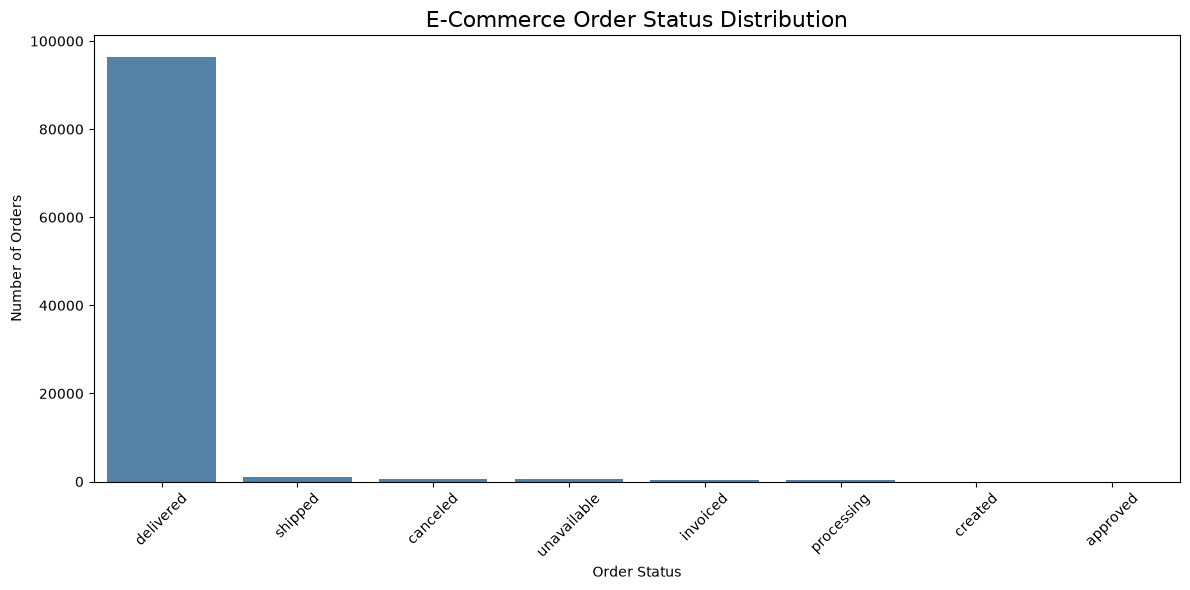

In [21]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    color="steelblue"
)

plt.title("E-Commerce Order Status Distribution", fontsize=16)
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
# Convert date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Check data types
print(orders[date_columns].dtypes)

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


In [23]:
# Select delivered orders
delivered_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Calculate delivery time in days
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate delay relative to estimated delivery
delivered_orders["delay_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Show summary
print("Average Delivery Days:",
      round(delivered_orders["delivery_days"].mean(), 2))

print("Median Delivery Days:",
      round(delivered_orders["delivery_days"].median(), 2))

print("Late Delivery Percentage:",
      round((delivered_orders["delay_days"] > 0).mean() * 100, 2))

Average Delivery Days: 12.56
Median Delivery Days: 10.22
Late Delivery Percentage: 8.11


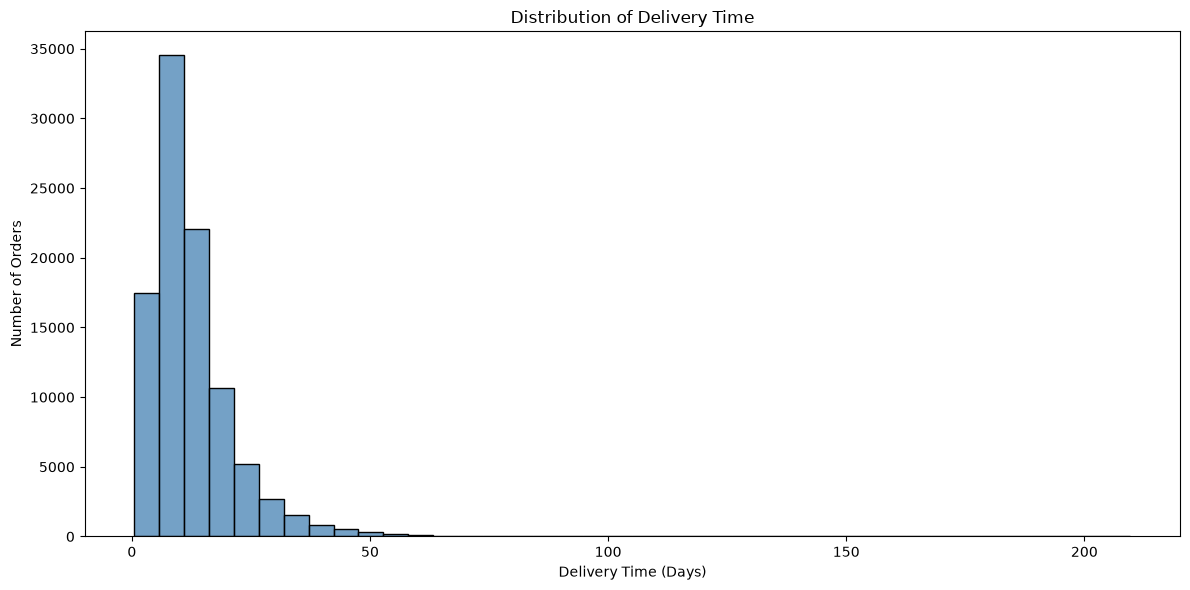

In [24]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=delivered_orders,
    x="delivery_days",
    bins=40,
    color="steelblue"
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

delivery_status
On Time    88644
Late        7826
Name: count, dtype: int64


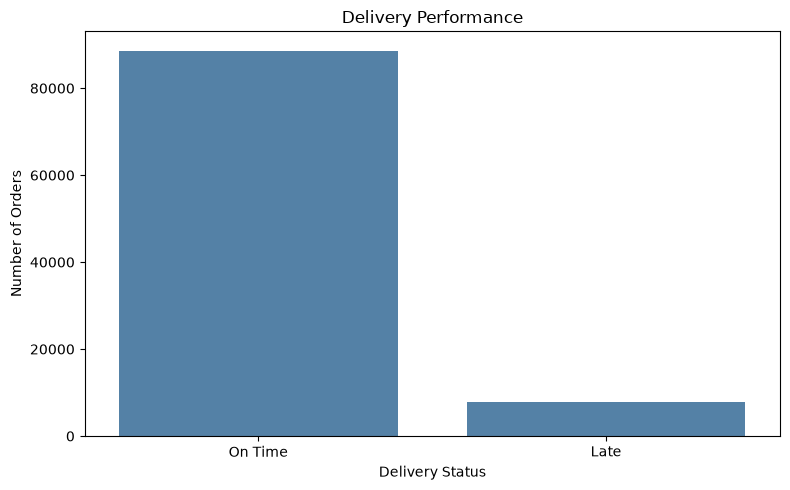

In [25]:
# Classify deliveries
delivered_orders["delivery_status"] = (
    delivered_orders["delay_days"]
    .apply(lambda x: "Late" if x > 0 else "On Time")
)

# Count orders by delivery status
delivery_counts = (
    delivered_orders["delivery_status"].value_counts()
)

print(delivery_counts)

# Create chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values,
    color="steelblue"
)

plt.title("Delivery Performance")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [26]:
import pandas as pd
from pathlib import Path

# تحديد مكان البيانات
data_path = Path("../DATA/RAW")

# قراءة ملف المبيعات
order_items = pd.read_csv(
    data_path / "olist_order_items_dataset (6).csv"
)

# عرض أول 5 صفوف
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [27]:
# Total product sales
total_sales = order_items["price"].sum()

# Total shipping fees
total_freight = order_items["freight_value"].sum()

# Number of unique orders
total_orders = order_items["order_id"].nunique()

# Average order value (excluding shipping)
average_order_value = total_sales / total_orders

# Total number of order items
total_items = len(order_items)

print("Total Product Sales: R$", round(total_sales, 2))
print("Total Freight Value: R$", round(total_freight, 2))
print("Total Orders:", total_orders)
print("Average Order Value: R$", round(average_order_value, 2))
print("Total Items:", total_items)

Total Product Sales: R$ 13591643.7
Total Freight Value: R$ 2251909.54
Total Orders: 98666
Average Order Value: R$ 137.75
Total Items: 112650


In [28]:
# Load orders if not already loaded
orders = pd.read_csv(
    data_path / "olist_orders_dataset (7).csv"
)

# Convert purchase date
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

# Merge order items with orders
sales_data = order_items.merge(
    orders[["order_id", "order_purchase_timestamp", "order_status"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

print("Merged Dataset Shape:", sales_data.shape)

sales_data.head()

Merged Dataset Shape: (112650, 9)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,order_status
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,delivered
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,delivered
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,delivered
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,delivered
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,delivered


In [29]:
# Create month column
sales_data["month"] = (
    sales_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Calculate monthly sales
monthly_sales = (
    sales_data.groupby("month")["price"]
    .sum()
    .sort_index()
)

print(monthly_sales)

month
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Freq: M, Name: price, dtype: float64


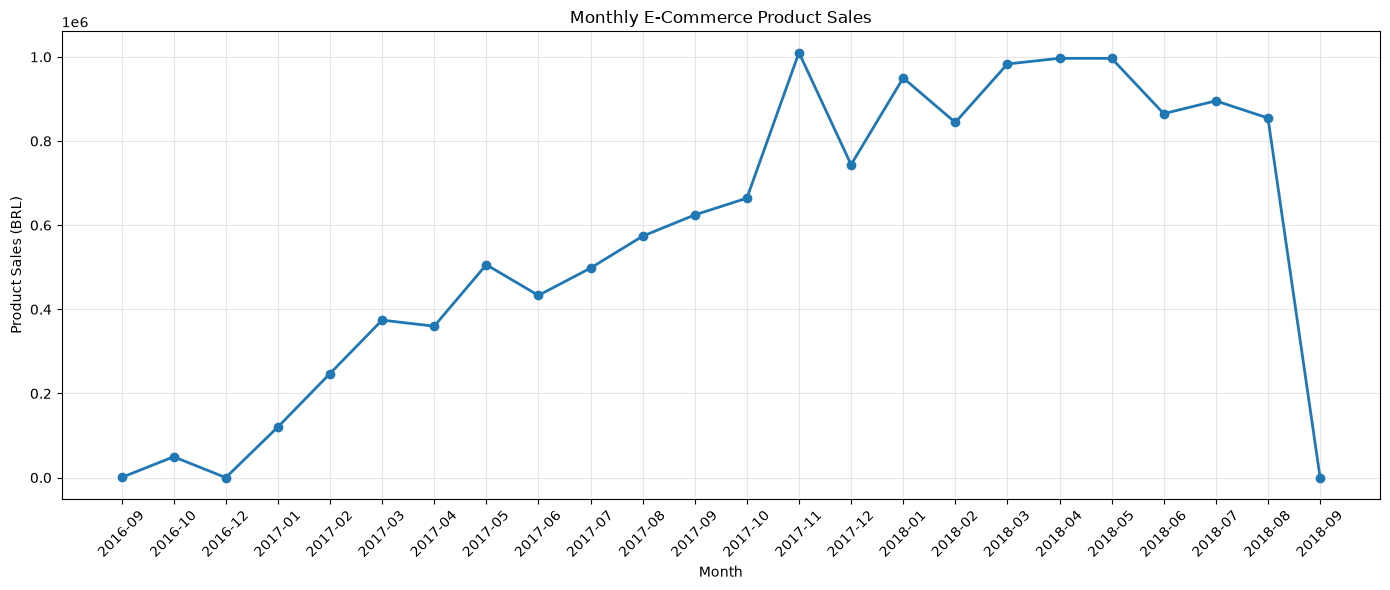

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly E-Commerce Product Sales")
plt.xlabel("Month")
plt.ylabel("Product Sales (BRL)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# Create monthly sales analysis table
monthly_analysis = monthly_sales.to_frame(name="sales")

# Calculate monthly growth percentage
monthly_analysis["growth_pct"] = (
    monthly_analysis["sales"].pct_change() * 100
)

# Display results
print(monthly_analysis.round(2))

              sales  growth_pct
month                          
2016-09      267.36         NaN
2016-10    49507.66    18417.23
2016-12       10.90      -99.98
2017-01   120312.87  1103687.80
2017-02   247303.02      105.55
2017-03   374344.30       51.37
2017-04   359927.23       -3.85
2017-05   506071.14       40.60
2017-06   433038.60      -14.43
2017-07   498031.48       15.01
2017-08   573971.68       15.25
2017-09   624401.69        8.79
2017-10   664219.43        6.38
2017-11  1010271.37       52.10
2017-12   743914.17      -26.36
2018-01   950030.36       27.71
2018-02   844178.71      -11.14
2018-03   983213.44       16.47
2018-04   996647.75        1.37
2018-05   996517.68       -0.01
2018-06   865124.31      -13.19
2018-07   895507.22        3.51
2018-08   854686.33       -4.56
2018-09      145.00      -99.98


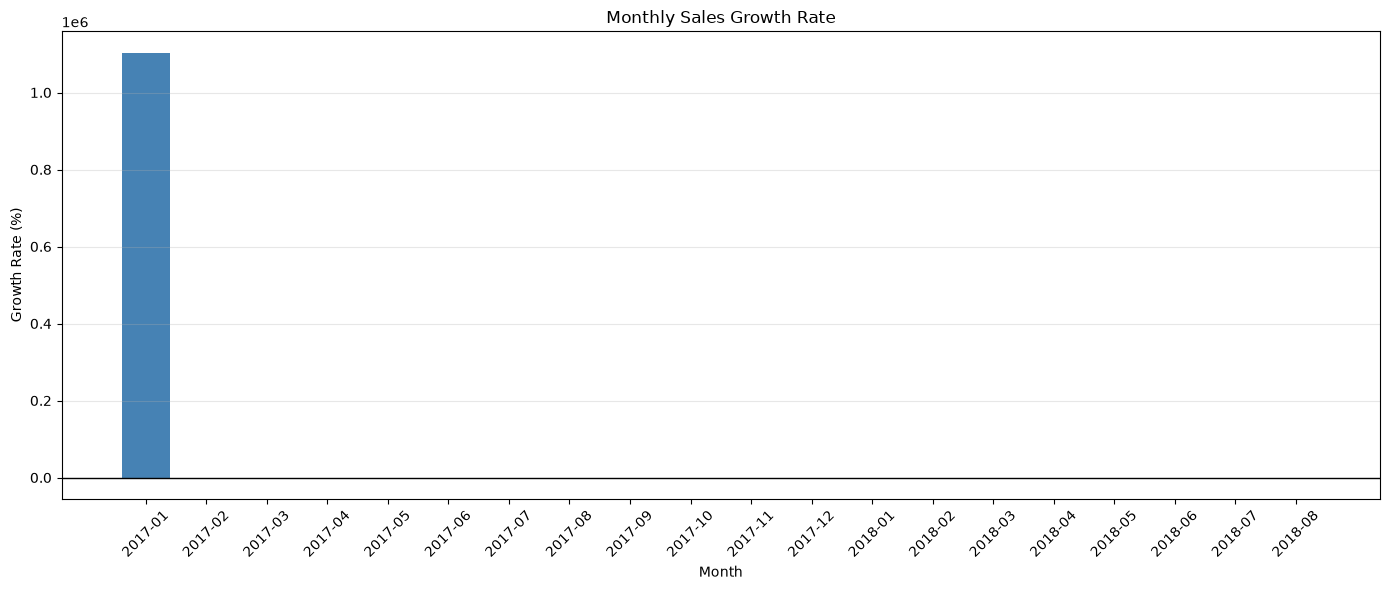

In [32]:
import matplotlib.pyplot as plt

# Exclude incomplete boundary months
growth_chart = monthly_analysis.loc["2017-01":"2018-08"].copy()

plt.figure(figsize=(14, 6))

plt.bar(
    growth_chart.index.astype(str),
    growth_chart["growth_pct"],
    color="steelblue"
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Monthly Sales Growth Rate")
plt.xlabel("Month")
plt.ylabel("Growth Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
import pandas as pd
from pathlib import Path

data_path = Path("../DATA/RAW")

# Load products dataset
products = pd.read_csv(
    data_path / "olist_products_dataset (6).csv"
)

# Display first 5 rows
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [34]:
category_translation = pd.read_csv(
    data_path / "product_category_name_translation (5).csv"
)

category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [35]:
# Merge order items with products
product_sales = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Merge with category translation
product_sales = product_sales.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# Check result
print("Total rows:", len(product_sales))
print("Missing categories:",
      product_sales["product_category_name_english"].isna().sum())

product_sales.head()

Total rows: 112650
Missing categories: 1627


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools


In [36]:
top_categories = (
    product_sales
    .dropna(subset=["product_category_name_english"])
    .groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Product Categories by Sales:")
print(top_categories.round(2))

Top 10 Product Categories by Sales:
product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64


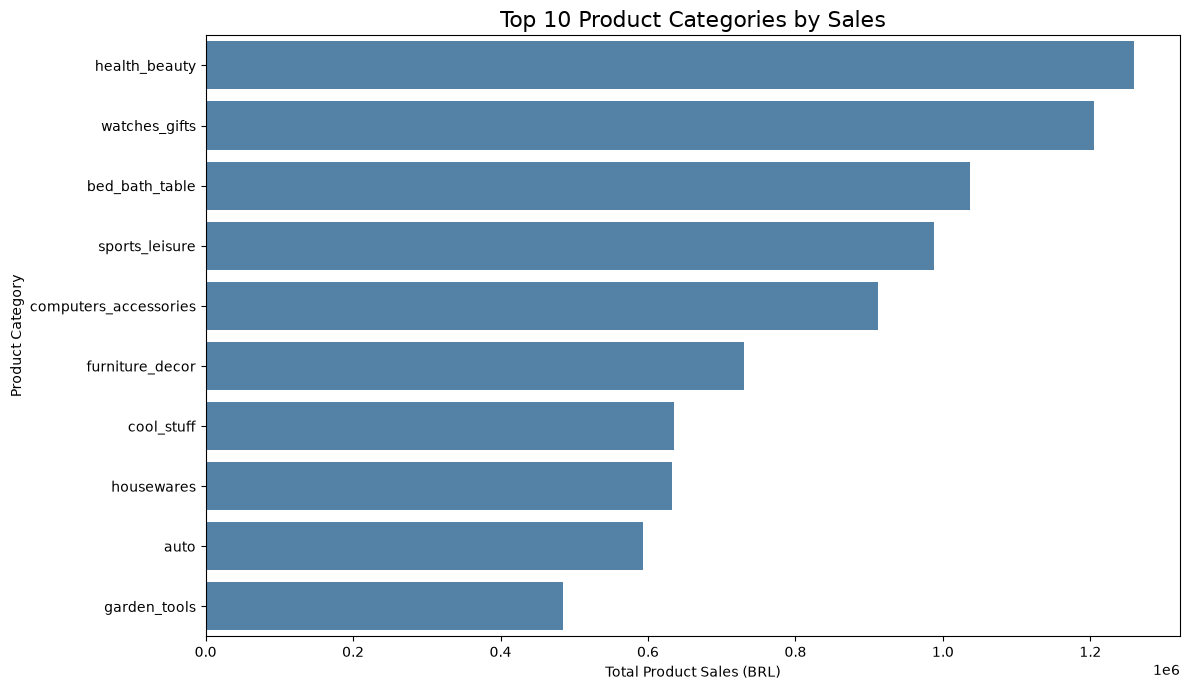

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index,
    color="steelblue"
)

plt.title("Top 10 Product Categories by Sales", fontsize=16)
plt.xlabel("Total Product Sales (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [38]:
import pandas as pd
from pathlib import Path

data_path = Path("../DATA/RAW")

# Load customers dataset
customers = pd.read_csv(
    data_path / "olist_customers_dataset (9).csv"
)

print("Total Customer Records:", len(customers))

customers.head()

Total Customer Records: 99441


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [39]:
total_customers = customers["customer_unique_id"].nunique()

total_cities = customers["customer_city"].nunique()

total_states = customers["customer_state"].nunique()

print("Unique Customers:", total_customers)
print("Total Cities:", total_cities)
print("Total States:", total_states)

Unique Customers: 96096
Total Cities: 4119
Total States: 27


In [40]:
# Count unique customers per state
state_customers = (
    customers.groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 States by Unique Customers:")
print(state_customers)

Top 10 States by Unique Customers:
customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
Name: customer_unique_id, dtype: int64


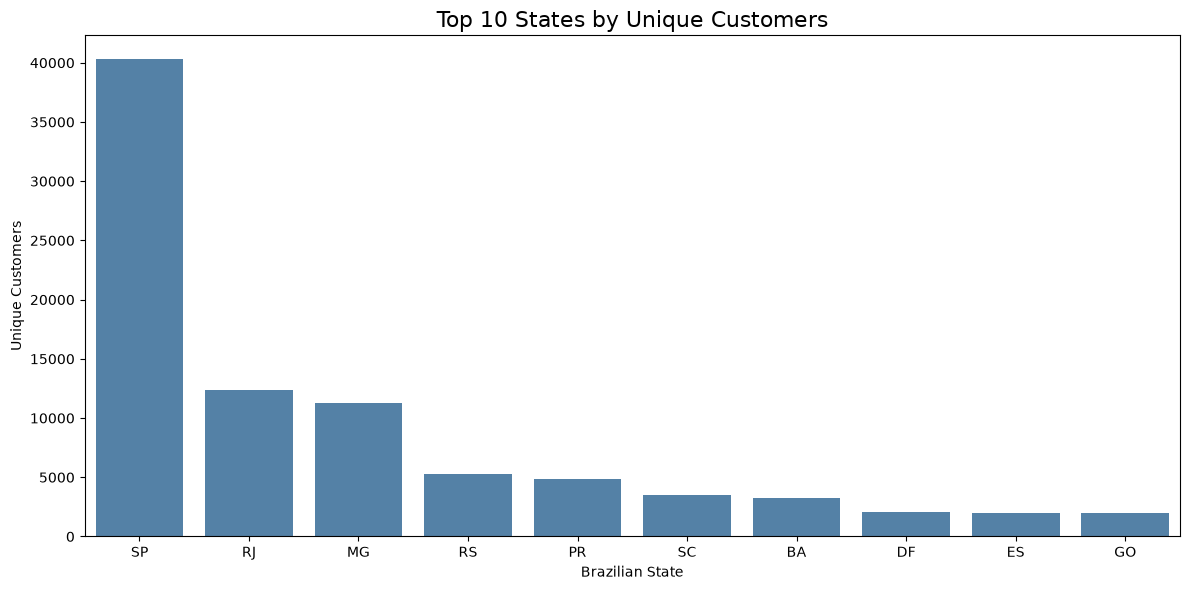

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    x=state_customers.index,
    y=state_customers.values,
    color="steelblue"
)

plt.title("Top 10 States by Unique Customers", fontsize=16)
plt.xlabel("Brazilian State")
plt.ylabel("Unique Customers")

plt.tight_layout()
plt.show()

In [42]:
import pandas as pd

# Load required datasets
customers = pd.read_csv(
    data_path / "olist_customers_dataset (9).csv"
)

orders = pd.read_csv(
    data_path / "olist_orders_dataset (7).csv"
)

# Convert purchase date
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

# Merge orders with customers
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="inner",
    validate="many_to_one"
)

# Merge with order items
rfm_data = customer_orders.merge(
    order_items[["order_id", "price"]],
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# Keep delivered orders only
rfm_data = rfm_data[
    rfm_data["order_status"] == "delivered"
].copy()

print("RFM Dataset Shape:", rfm_data.shape)

rfm_data.head()

RFM Dataset Shape: (110197, 10)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,price
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,19.90


In [43]:
# Set analysis date
snapshot_date = (
    rfm_data["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

# Calculate RFM metrics
rfm = rfm_data.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
)

# Calculate recency in days
rfm["recency"] = (
    snapshot_date - rfm["last_purchase"]
).dt.days

# Organize columns
rfm = rfm[["recency", "frequency", "monetary"]]

print("Total Customers:", len(rfm))

rfm.head()

Total Customers: 93358


,recency,frequency,monetary
customer_unique_id,,,
0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
0000f46a3911fa3c0805444483337064,537,1,69.00
0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
0004aac84e0df4da2b147fca70cf8255,288,1,180.00


In [44]:
print("RFM Summary Statistics:")
print(rfm.describe().round(2))

print("\nCustomers with Multiple Orders:")
print((rfm["frequency"] > 1).sum())

print("\nTop 10 Customers by Monetary Value:")
print(
    rfm.sort_values(
        "monetary",
        ascending=False
    ).head(10)
)

RFM Summary Statistics:
        recency  frequency  monetary
count  93358.00   93358.00  93358.00
mean     237.94       1.03    141.62
std      152.59       0.21    215.69
min        1.00       1.00      0.85
25%      114.00       1.00     47.65
50%      219.00       1.00     89.73
75%      346.00       1.00    154.74
max      714.00      15.00  13440.00

Customers with Multiple Orders:
2801

Top 10 Customers by Monetary Value:
                                  recency  frequency  monetary
customer_unique_id                                            
0a0a92112bd4c708ca5fde585afaa872      334          1   13440.0
da122df9eeddfedc1dc1f5349a1a690c      515          2    7388.0
763c8b1c9c68a0229c42c9fc6f662b93       46          1    7160.0
dc4802a71eae9be1dd28f5d788ceb526      563          1    6735.0
459bef486812aa25204be022145caa62       35          1    6729.0
ff4159b92c40ebe40454e3e6a7c35ed6      462          1    6499.0
4007669dec559734d6f53e029e360987      279          1    5934.6
e

In [45]:
# Recency score: lower recency is better
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first", ascending=False),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Frequency score: more orders is better
# Use business-friendly bins because most customers have 1 order
rfm["F_score"] = (
    rfm["frequency"]
    .apply(lambda x: 1 if x == 1 else
                     3 if x == 2 else 5)
)

# Monetary score: higher spending is better
rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm[[
    "recency", "frequency", "monetary",
    "R_score", "F_score", "M_score"
]].head()

,recency,frequency,monetary,R_score,F_score,M_score
customer_unique_id,,,,,,
0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,4
0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1
0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2
0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1
0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,5


In [46]:
def segment_customer(row):
    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 3 and m >= 4:
        return "Champions"
    elif f >= 3 and r >= 3:
        return "Loyal Customers"
    elif r >= 4 and m >= 4:
        return "High Value New"
    elif r <= 2 and m >= 4:
        return "At Risk"
    elif r >= 4:
        return "Recent Customers"
    else:
        return "Other Customers"

rfm["segment"] = rfm.apply(segment_customer, axis=1)

print("Customer Segments:")
print(rfm["segment"].value_counts())

Customer Segments:
segment
Other Customers     40890
Recent Customers    21662
At Risk             14518
High Value New      14478
Champions             932
Loyal Customers       878
Name: count, dtype: int64


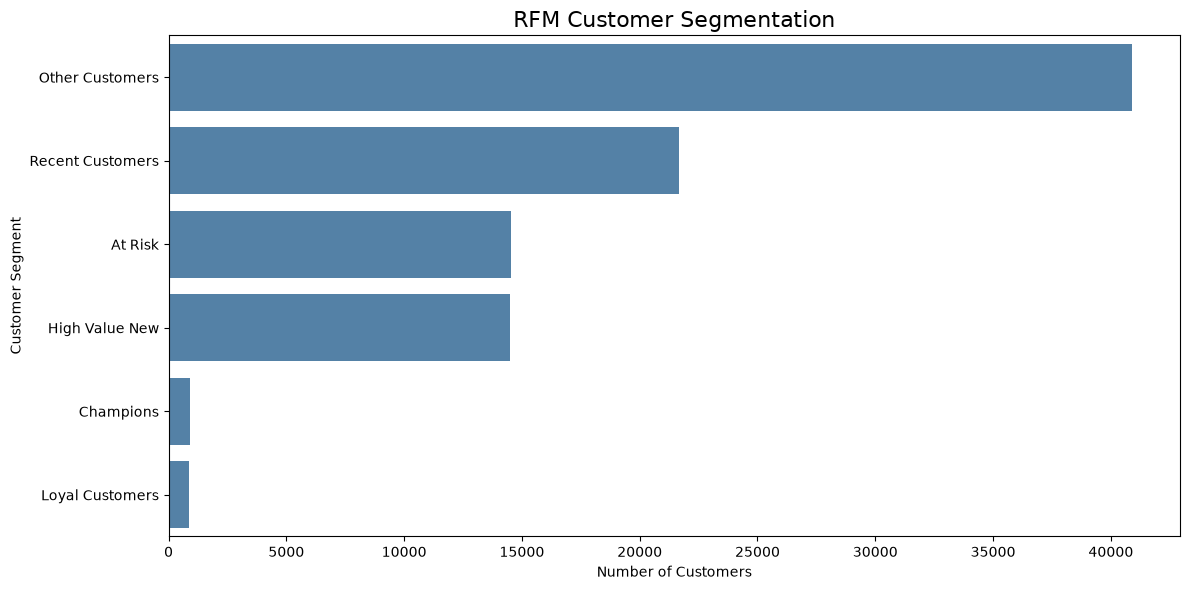

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

segment_counts = rfm["segment"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=segment_counts.values,
    y=segment_counts.index,
    color="steelblue"
)

plt.title("RFM Customer Segmentation", fontsize=16)
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

In [48]:
# Customer Segment Revenue Analysis

segment_analysis = (
    rfm.groupby("segment")
    .agg(
        customers=("monetary", "size"),
        total_sales=("monetary", "sum"),
        avg_spending=("monetary", "mean"),
        avg_frequency=("frequency", "mean")
    )
    .sort_values("total_sales", ascending=False)
)

# Calculate sales contribution
segment_analysis["sales_percentage"] = (
    segment_analysis["total_sales"]
    / segment_analysis["total_sales"].sum()
    * 100
)

print("Customer Segment Revenue Analysis:")
print(segment_analysis.round(2))

Customer Segment Revenue Analysis:
                  customers  total_sales  avg_spending  avg_frequency  \
segment                                                                 
At Risk               14518   4042927.89        278.48           1.05   
High Value New        14478   3867908.88        267.16           1.00   
Other Customers       40890   3623785.03         88.62           1.01   
Recent Customers      21662   1202825.80         55.53           1.00   
Champions               932    304854.42        327.10           2.19   
Loyal Customers         878    179196.09        204.10           2.07   

                  sales_percentage  
segment                             
At Risk                      30.58  
High Value New               29.25  
Other Customers              27.41  
Recent Customers              9.10  
Champions                     2.31  
Loyal Customers               1.36  


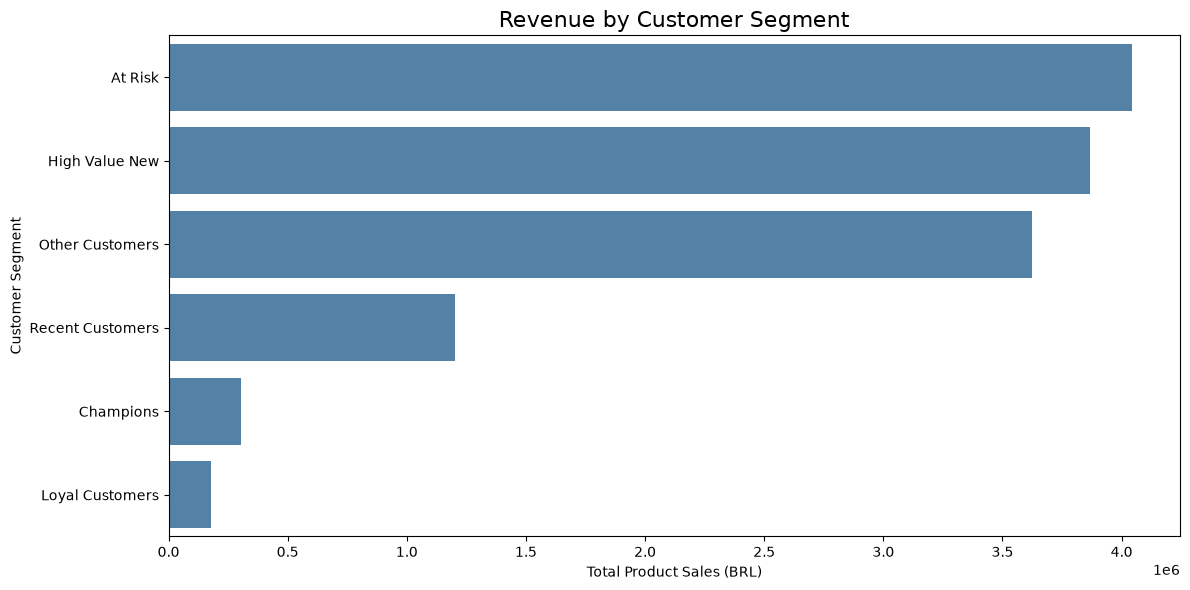

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    x=segment_analysis["total_sales"].values,
    y=segment_analysis.index,
    color="steelblue"
)

plt.title("Revenue by Customer Segment", fontsize=16)
plt.xlabel("Total Product Sales (BRL)")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

In [50]:
segment_analysis["customer_percentage"] = (
    segment_analysis["customers"]
    / segment_analysis["customers"].sum()
    * 100
)

print(
    segment_analysis[
        ["customers", "customer_percentage",
         "total_sales", "sales_percentage"]
    ].round(2)
)

                  customers  customer_percentage  total_sales  \
segment                                                         
At Risk               14518                15.55   4042927.89   
High Value New        14478                15.51   3867908.88   
Other Customers       40890                43.80   3623785.03   
Recent Customers      21662                23.20   1202825.80   
Champions               932                 1.00    304854.42   
Loyal Customers         878                 0.94    179196.09   

                  sales_percentage  
segment                             
At Risk                      30.58  
High Value New               29.25  
Other Customers              27.41  
Recent Customers              9.10  
Champions                     2.31  
Loyal Customers               1.36  


In [51]:
import pandas as pd
from pathlib import Path

data_path = Path("../DATA/RAW")

# Load customers
customers = pd.read_csv(
    data_path / "olist_customers_dataset (9).csv"
)

# Load orders
orders = pd.read_csv(
    data_path / "olist_orders_dataset (7).csv"
)

# Convert purchase date to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

# Keep delivered orders
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Merge orders with customers
customer_orders = delivered_orders.merge(
    customers[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="inner"
)

print("Total Delivered Orders:", len(customer_orders))
print(
    "Unique Customers:",
    customer_orders["customer_unique_id"].nunique()
)

customer_orders.head()

Total Delivered Orders: 96478
Unique Customers: 93358


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6


In [52]:
# Extract purchase month
customer_orders["order_month"] = (
    customer_orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Find first purchase month for each customer
customer_orders["cohort_month"] = (
    customer_orders.groupby("customer_unique_id")[
        "order_month"
    ].transform("min")
)

# Calculate months since first purchase
customer_orders["cohort_index"] = (
    (customer_orders["order_month"].dt.year -
     customer_orders["cohort_month"].dt.year) * 12
    +
    (customer_orders["order_month"].dt.month -
     customer_orders["cohort_month"].dt.month)
    + 1
)

customer_orders[
    ["customer_unique_id", "order_month",
     "cohort_month", "cohort_index"]
].head()

,customer_unique_id,order_month,cohort_month,cohort_index
0,7c396fd4830fd04220f754e42b4e5bff,2017-10,2017-09,2
1,af07308b275d755c9edb36a90c618231,2018-07,2018-07,1
2,3a653a41f6f9fc3d2a113cf8398680e8,2018-08,2018-08,1
3,7c142cf63193a1473d2e66489a9ae977,2017-11,2017-11,1
4,72632f0f9dd73dfee390c9b22eb56dd6,2018-02,2018-02,1


In [53]:
# Count unique customers per cohort and month
cohort_data = (
    customer_orders
    .groupby(["cohort_month", "cohort_index"])
    ["customer_unique_id"]
    .nunique()
    .reset_index(name="customers")
)

# Create cohort matrix
cohort_matrix = cohort_data.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customers"
)

print("Cohort Matrix:")
display(cohort_matrix.head())

Cohort Matrix:


cohort_index,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,2.0
2016-12,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.0,2.0,2.0,1.0,3.0,1.0,3.0,1.0,1.0,NaN,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,1.0,NaN
2017-02,1628.0,3.0,5.0,2.0,7.0,2.0,4.0,3.0,2.0,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,3.0,NaN,NaN


In [54]:
# Number of customers in first month
cohort_sizes = cohort_matrix[1]

# Calculate retention percentage
retention_matrix = (
    cohort_matrix.div(cohort_sizes, axis=0) * 100
)

print("Customer Retention Rate (%):")
display(retention_matrix.round(2))

Customer Retention Rate (%):


cohort_index,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.38,NaN,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,0.76,0.76
2016-12,100.0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,NaN,NaN
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,NaN,NaN,NaN
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,NaN,NaN,NaN,NaN
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,NaN,NaN,NaN,NaN,NaN


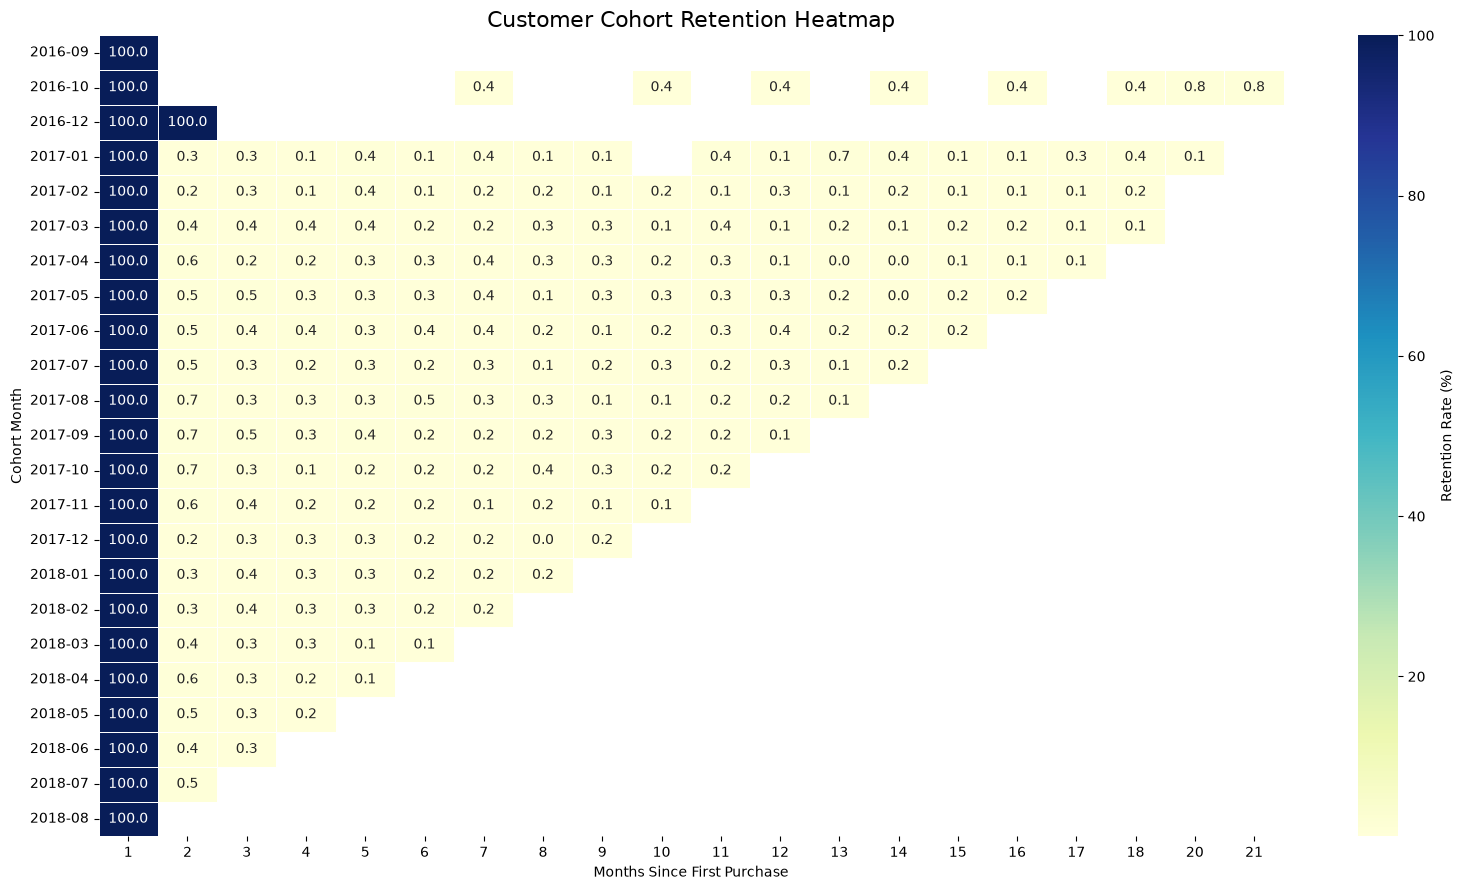

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 9))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Retention Rate (%)"}
)

plt.title(
    "Customer Cohort Retention Heatmap",
    fontsize=16
)

plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")

plt.tight_layout()
plt.show()

In [56]:
# Retention KPI Analysis

# Last observed purchase month
last_month = customer_orders["order_month"].max()

# Calculate retention only for cohorts with
# enough time to reach the target month
def weighted_retention(months_after_first):
    eligible = cohort_sizes.index[
        cohort_sizes.index <= last_month - months_after_first
    ]

    if len(eligible) == 0:
        return float("nan")

    retained = (
        cohort_matrix
        .reindex(
            index=eligible,
            columns=[months_after_first + 1],
            fill_value=0
        )
        .fillna(0)
        .iloc[:, 0]
        .sum()
    )

    total = cohort_sizes.loc[eligible].sum()

    return retained / total * 100


month_1 = weighted_retention(1)
month_3 = weighted_retention(3)
month_6 = weighted_retention(6)

# Repeat Purchase Rate
customer_frequency = (
    customer_orders.groupby("customer_unique_id")[
        "order_id"
    ].nunique()
)

repeat_purchase_rate = (
    (customer_frequency > 1).mean() * 100
)

print(f"Month 1 Retention: {month_1:.2f}%")
print(f"Month 3 Retention: {month_3:.2f}%")
print(f"Month 6 Retention: {month_6:.2f}%")
print(f"Repeat Purchase Rate: {repeat_purchase_rate:.2f}%")

Month 1 Retention: 0.48%
Month 3 Retention: 0.25%
Month 6 Retention: 0.23%
Repeat Purchase Rate: 3.00%


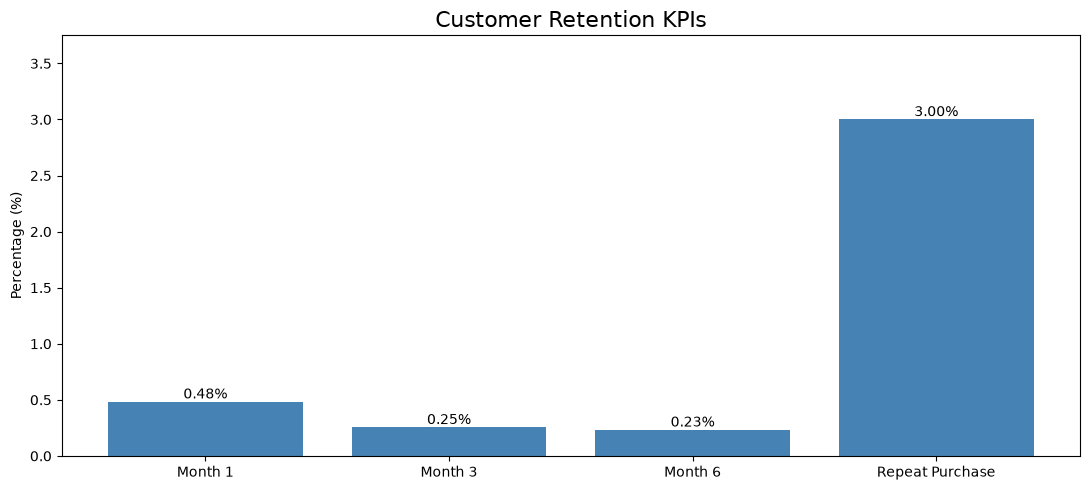

In [57]:
import matplotlib.pyplot as plt

kpi_names = [
    "Month 1",
    "Month 3",
    "Month 6",
    "Repeat Purchase"
]

kpi_values = [
    month_1,
    month_3,
    month_6,
    repeat_purchase_rate
]

plt.figure(figsize=(11, 5))

bars = plt.bar(
    kpi_names,
    kpi_values,
    color="steelblue"
)

plt.title("Customer Retention KPIs", fontsize=16)
plt.ylabel("Percentage (%)")

for bar, value in zip(bars, kpi_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.ylim(0, max(kpi_values) * 1.25)
plt.tight_layout()
plt.show()

In [58]:
# Historical Customer Value Analysis

customer_value = rfm.copy()

customer_value["historical_value"] = (
    customer_value["monetary"]
)

print("Customer Value Statistics:")
print(customer_value["historical_value"].describe().round(2))

print("\nTop 10 Customers:")
display(
    customer_value.sort_values(
        "historical_value",
        ascending=False
    ).head(10)
)

Customer Value Statistics:
count    93358.00
mean       141.62
std        215.69
min          0.85
25%         47.65
50%         89.73
75%        154.74
max      13440.00
Name: historical_value, dtype: float64

Top 10 Customers:


,recency,frequency,monetary,R_score,F_score,M_score,segment,historical_value
customer_unique_id,,,,,,,,
0a0a92112bd4c708ca5fde585afaa872,334,1,13440.0,2,1,5,At Risk,13440.0
da122df9eeddfedc1dc1f5349a1a690c,515,2,7388.0,1,3,5,At Risk,7388.0
763c8b1c9c68a0229c42c9fc6f662b93,46,1,7160.0,5,1,5,High Value New,7160.0
dc4802a71eae9be1dd28f5d788ceb526,563,1,6735.0,1,1,5,At Risk,6735.0
459bef486812aa25204be022145caa62,35,1,6729.0,5,1,5,High Value New,6729.0
ff4159b92c40ebe40454e3e6a7c35ed6,462,1,6499.0,1,1,5,At Risk,6499.0
4007669dec559734d6f53e029e360987,279,1,5934.6,2,1,5,At Risk,5934.6
eebb5dda148d3893cdaf5b5ca3040ccb,498,1,4690.0,1,1,5,At Risk,4690.0
48e1ac109decbb87765a3eade6854098,69,1,4590.0,5,1,5,High Value New,4590.0


In [59]:
# Customer Value Segmentation

customer_value["value_segment"] = pd.qcut(
    customer_value["historical_value"].rank(method="first"),
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "VIP Customers"
    ]
)

value_analysis = (
    customer_value.groupby(
        "value_segment",
        observed=True
    )
    .agg(
        customers=("historical_value", "size"),
        total_value=("historical_value", "sum"),
        avg_value=("historical_value", "mean")
    )
)

value_analysis["revenue_share"] = (
    value_analysis["total_value"]
    / value_analysis["total_value"].sum()
    * 100
)

display(value_analysis.round(2))

,customers,total_value,avg_value,revenue_share
value_segment,,,,
Low Value,23340,679200.46,29.10,5.14
Medium Value,23339,1527063.09,65.43,11.55
High Value,23339,2747817.32,117.74,20.78
VIP Customers,23340,8267417.24,354.22,62.53


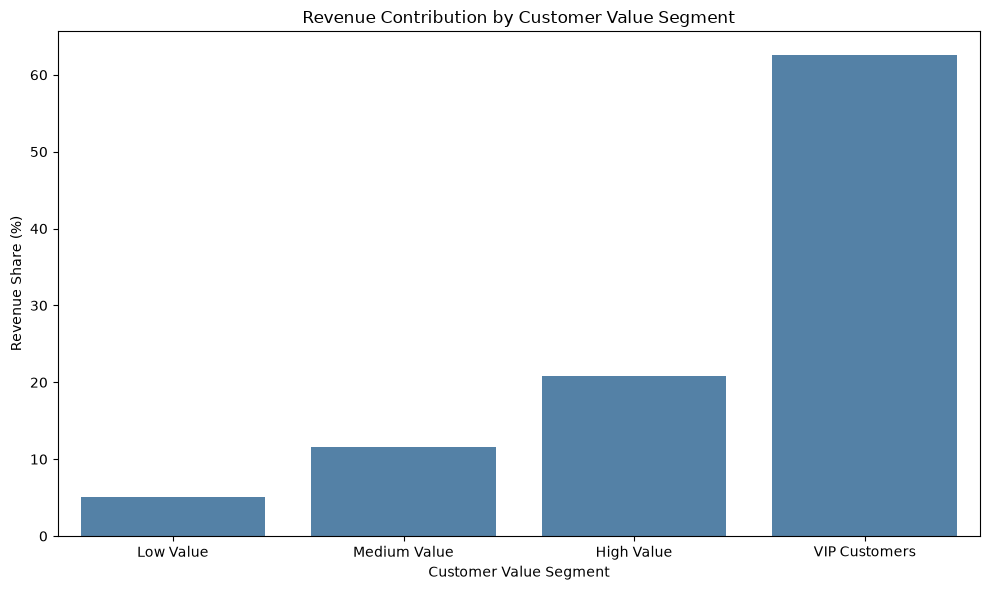

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    x=value_analysis.index.astype(str),
    y=value_analysis["revenue_share"].values,
    color="steelblue"
)

plt.title("Revenue Contribution by Customer Value Segment")
plt.xlabel("Customer Value Segment")
plt.ylabel("Revenue Share (%)")

plt.tight_layout()
plt.show()

In [61]:
import pandas as pd
import numpy as np

# Sort customers by historical spending
pareto = customer_value[
    ["historical_value"]
].sort_values(
    "historical_value",
    ascending=False
).copy()

# Calculate cumulative sales
pareto["cumulative_sales"] = (
    pareto["historical_value"].cumsum()
)

# Calculate cumulative sales percentage
pareto["cumulative_sales_pct"] = (
    pareto["cumulative_sales"]
    / pareto["historical_value"].sum()
    * 100
)

# Calculate cumulative customer percentage
pareto["cumulative_customers_pct"] = (
    np.arange(1, len(pareto) + 1)
    / len(pareto)
    * 100
)

pareto.head()

,historical_value,cumulative_sales,cumulative_sales_pct,cumulative_customers_pct
customer_unique_id,,,,
0a0a92112bd4c708ca5fde585afaa872,13440.0,13440.0,0.101653,0.001071
da122df9eeddfedc1dc1f5349a1a690c,7388.0,20828.0,0.157531,0.002142
763c8b1c9c68a0229c42c9fc6f662b93,7160.0,27988.0,0.211686,0.003213
dc4802a71eae9be1dd28f5d788ceb526,6735.0,34723.0,0.262625,0.004285
459bef486812aa25204be022145caa62,6729.0,41452.0,0.313520,0.005356


In [62]:
# Number of customers in top 20%
top_20_count = int(np.ceil(len(pareto) * 0.20))

# Sales generated by top 20%
top_20_sales = (
    pareto["historical_value"]
    .head(top_20_count)
    .sum()
)

# Percentage of total sales
top_20_percentage = (
    top_20_sales
    / pareto["historical_value"].sum()
    * 100
)

# Percentage of customers needed for 80% of sales
customers_for_80 = (
    np.searchsorted(
        pareto["cumulative_sales_pct"].to_numpy(),
        80,
        side="left"
    ) + 1
)

customers_for_80_pct = (
    customers_for_80 / len(pareto) * 100
)

print(f"Top 20% Customers Revenue: {top_20_percentage:.2f}%")
print(f"Customers Needed for 80% Revenue: {customers_for_80_pct:.2f}%")

Top 20% Customers Revenue: 56.62%
Customers Needed for 80% Revenue: 45.00%


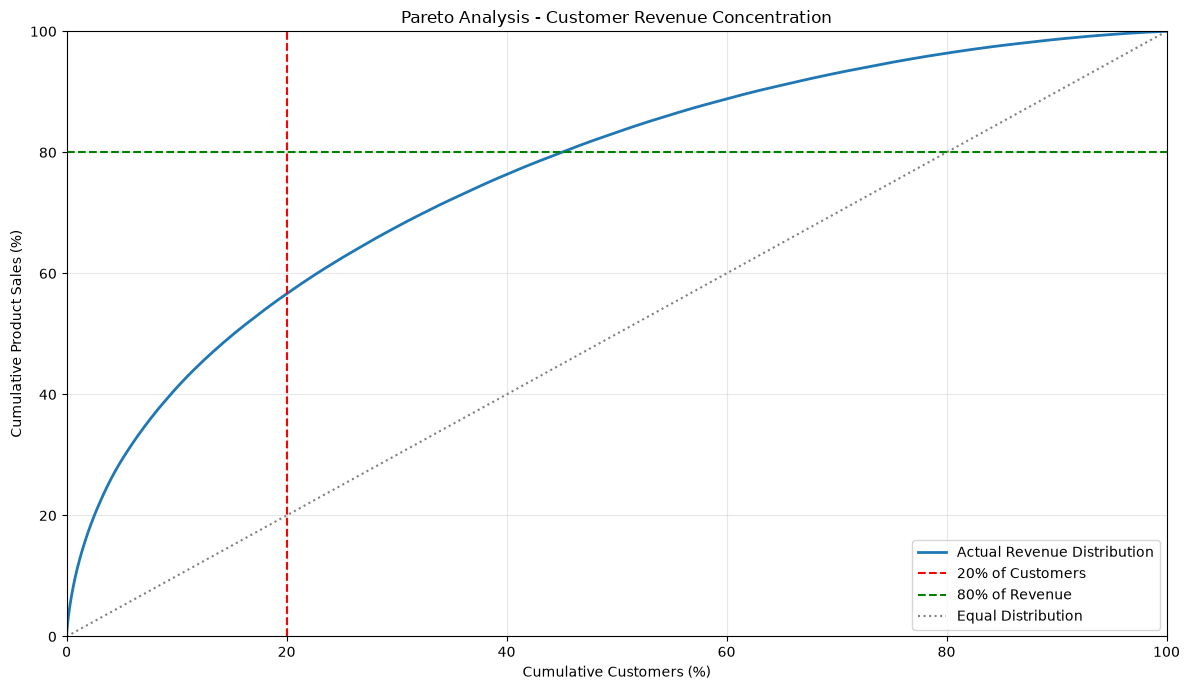

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.plot(
    pareto["cumulative_customers_pct"],
    pareto["cumulative_sales_pct"],
    linewidth=2,
    label="Actual Revenue Distribution"
)

# Reference lines for 80/20 rule
plt.axvline(
    x=20,
    color="red",
    linestyle="--",
    label="20% of Customers"
)

plt.axhline(
    y=80,
    color="green",
    linestyle="--",
    label="80% of Revenue"
)

plt.plot(
    [0, 100],
    [0, 100],
    color="gray",
    linestyle=":",
    label="Equal Distribution"
)

plt.title("Pareto Analysis - Customer Revenue Concentration")
plt.xlabel("Cumulative Customers (%)")
plt.ylabel("Cumulative Product Sales (%)")

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [64]:
# Customer Revenue Concentration Analysis

percentiles = [1, 5, 10, 20, 50]

total_revenue = pareto["historical_value"].sum()
total_customers = len(pareto)

results = []

for pct in percentiles:

    customer_count = int(
        np.ceil(total_customers * pct / 100)
    )

    revenue = (
        pareto["historical_value"]
        .head(customer_count)
        .sum()
    )

    revenue_share = revenue / total_revenue * 100

    results.append({
        "Top Customers (%)": pct,
        "Number of Customers": customer_count,
        "Revenue (BRL)": round(revenue, 2),
        "Revenue Share (%)": round(revenue_share, 2)
    })

concentration_df = pd.DataFrame(results)

concentration_df

,Top Customers (%),Number of Customers,Revenue (BRL),Revenue Share (%)
0,1,934,1515932.84,11.47
1,5,4668,3851392.14,29.13
2,10,9336,5434024.58,41.10
3,20,18672,7486237.06,56.62
4,50,46679,11015234.56,83.31


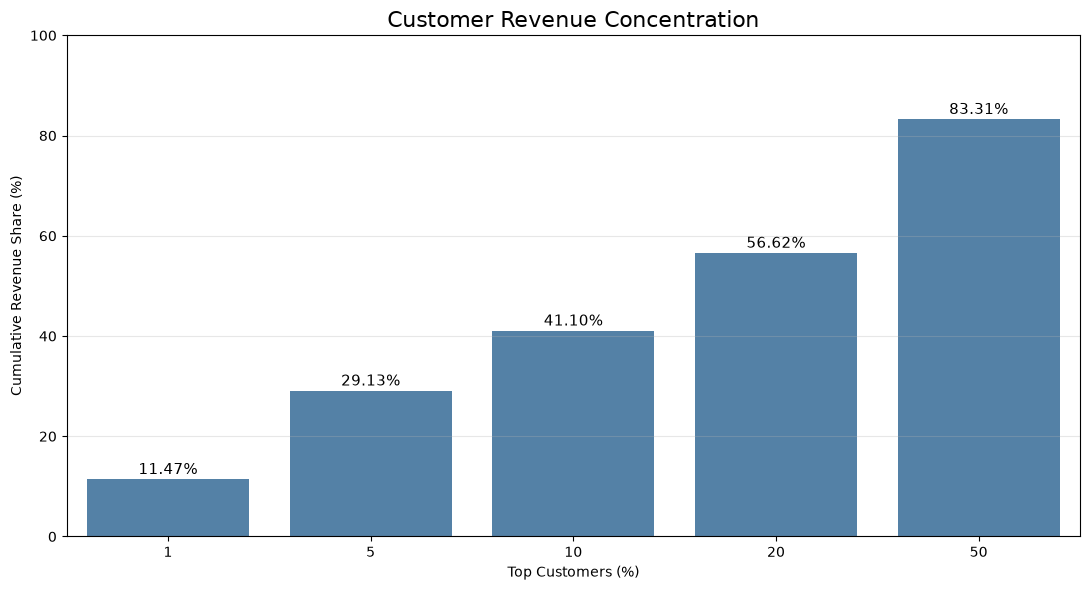

In [65]:

import matplotlib.pyplot as plt
import seaborn as sns

# Customer Revenue Concentration Visualization

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=concentration_df,
    x="Top Customers (%)",
    y="Revenue Share (%)",
    color="steelblue"
)

# Add percentage labels
for bar in ax.patches:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center",
        fontsize=11
    )

plt.title(
    "Customer Revenue Concentration",
    fontsize=16
)

plt.xlabel("Top Customers (%)")
plt.ylabel("Cumulative Revenue Share (%)")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [66]:

# Customer Purchase Behavior Analysis

# Count unique orders for each customer
customer_frequency = (
    customer_orders
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

# Count one-time customers
one_time_customers = (
    customer_frequency == 1
).sum()

# Count repeat customers
repeat_customers = (
    customer_frequency > 1
).sum()

# Total unique customers
total_customers = len(customer_frequency)

# Calculate percentages
one_time_percentage = (
    one_time_customers / total_customers * 100
)

repeat_percentage = (
    repeat_customers / total_customers * 100
)

print("Customer Purchase Behavior")
print("--------------------------")

print("Total Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

print(
    "One-Time Customers (%):",
    round(one_time_percentage, 2)
)

print(
    "Repeat Customers (%):",
    round(repeat_percentage, 2)
)


Customer Purchase Behavior
--------------------------
Total Customers: 93358
One-Time Customers: 90557
Repeat Customers: 2801
One-Time Customers (%): 97.0
Repeat Customers (%): 3.0


Customer Purchase Frequency:
order_id
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


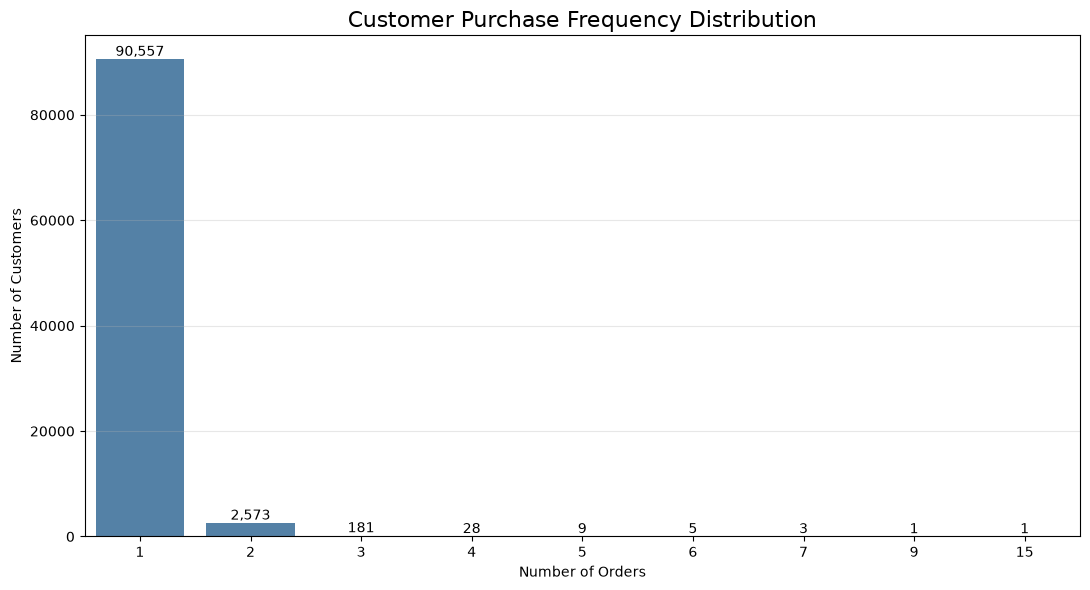

In [67]:

# Customer Purchase Frequency Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers by number of orders
frequency_distribution = (
    customer_frequency
    .value_counts()
    .sort_index()
)

print("Customer Purchase Frequency:")
print(frequency_distribution)

# Create visualization
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=frequency_distribution.index,
    y=frequency_distribution.values,
    color="steelblue"
)

# Add labels above bars
for bar in ax.patches:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.title(
    "Customer Purchase Frequency Distribution",
    fontsize=16
)

plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [68]:

# Customer Loyalty KPIs

# Total unique orders
total_orders = customer_frequency.sum()

# Average purchase frequency
average_frequency = (
    total_orders / total_customers
)

# Repeat purchase rate
repeat_purchase_rate = (
    repeat_customers / total_customers * 100
)

# Average orders per repeat customer
average_repeat_frequency = (
    customer_frequency[customer_frequency > 1].mean()
)

# Maximum orders by one customer
max_orders = customer_frequency.max()

print("Customer Loyalty KPIs")
print("----------------------------")

print("Total Customers:", total_customers)
print("Total Orders:", total_orders)

print(
    "Average Purchase Frequency:",
    round(average_frequency, 2)
)

print(
    "Repeat Purchase Rate:",
    round(repeat_purchase_rate, 2), "%"
)

print(
    "Average Orders per Repeat Customer:",
    round(average_repeat_frequency, 2)
)

print(
    "Maximum Orders by One Customer:",
    max_orders
)


Customer Loyalty KPIs
----------------------------
Total Customers: 93358
Total Orders: 96478
Average Purchase Frequency: 1.03
Repeat Purchase Rate: 3.0 %
Average Orders per Repeat Customer: 2.11
Maximum Orders by One Customer: 15


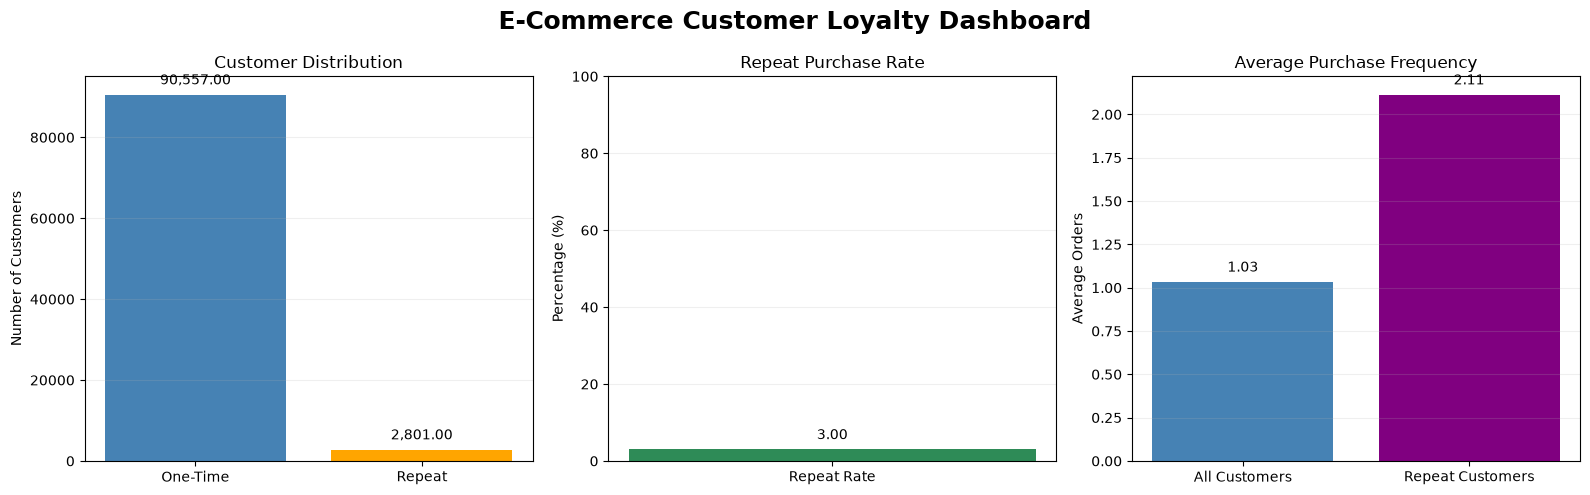

In [69]:

import matplotlib.pyplot as plt

# Customer Loyalty Dashboard

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Chart 1: Customer Distribution
axes[0].bar(
    ["One-Time", "Repeat"],
    [one_time_customers, repeat_customers],
    color=["steelblue", "orange"]
)

axes[0].set_title("Customer Distribution")
axes[0].set_ylabel("Number of Customers")

# Chart 2: Repeat Purchase Rate
axes[1].bar(
    ["Repeat Rate"],
    [repeat_purchase_rate],
    color="seagreen"
)

axes[1].set_title("Repeat Purchase Rate")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_ylim(0, 100)

# Chart 3: Purchase Frequency
axes[2].bar(
    ["All Customers", "Repeat Customers"],
    [average_frequency, average_repeat_frequency],
    color=["steelblue", "purple"]
)

axes[2].set_title("Average Purchase Frequency")
axes[2].set_ylabel("Average Orders")

# Add labels above bars
for ax in axes:
    for bar in ax.patches:
        height = bar.get_height()

        ax.annotate(
            f"{height:,.2f}",
            (
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            ha="center",
            va="bottom",
            xytext=(0, 5),
            textcoords="offset points"
        )

    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "E-Commerce Customer Loyalty Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [70]:

from pathlib import Path

# Project root
project_path = Path.cwd().parent

# Correct processed folder
processed_path = project_path / "DATA" / "processed"

# Create folder if it does not exist
processed_path.mkdir(parents=True, exist_ok=True)

print("Processed path:", processed_path)
print("Folder exists:", processed_path.is_dir())


Processed path: c:\DATA SCINENCE\Ecommerce-Data-Analysis\DATA\processed
Folder exists: True


In [71]:

# Export RFM analysis
rfm.to_csv(
    processed_path / "customer_rfm.csv"
)

# Export customer segmentation
segment_analysis.to_csv(
    processed_path / "customer_segments.csv"
)

# Export customer value segmentation
value_analysis.to_csv(
    processed_path / "customer_value_segments.csv"
)

# Export revenue concentration
concentration_df.to_csv(
    processed_path / "revenue_concentration.csv",
    index=False
)

print("All files exported successfully!")

# Verify exported files
for file in sorted(processed_path.glob("*.csv")):
    print(file.name)


All files exported successfully!
business_kpis.csv
customer_rfm.csv
customer_segments.csv
customer_value_segments.csv
revenue_concentration.csv


In [72]:

# Create Business KPIs table

business_kpis = pd.DataFrame({
    "metric": [
        "Total Product Sales",
        "Total Orders",
        "Total Customers",
        "Repeat Purchase Rate"
    ],
    "value": [
        total_sales,
        total_orders,
        total_customers,
        repeat_purchase_rate
    ]
})

business_kpis


,metric,value
0,Total Product Sales,1.359164e+07
1,Total Orders,9.647800e+04
2,Total Customers,9.335800e+04
3,Repeat Purchase Rate,3.000278e+00


In [73]:

# Export Business KPIs
business_kpis.to_csv(
    processed_path / "business_kpis.csv",
    index=False
)

print("Business KPIs exported successfully!")


Business KPIs exported successfully!
